# EGT309 Project: Predictive Maintenance. Exploratory Data Analysis

**Contents**
1. Problem and data overview
2. Data quality (structure, ranges, missing values, invalid values)
3. Univariate analysis *(next)*
4. Relationships with the target *(next)*
5. Leakage analysis of the derived columns *(next)*
6. Correlations and feature ideas *(next)*
7. Summary of findings *(next)*

## 1. Problem and data overview

### 1.1 Business problem

The AI Manufacturing Analytics team wants an **alert system** that flags when a machine is due for maintenance, so that unscheduled downtime during production runs is avoided.
The target is `maintenance_required` (0 = No, 1 = Yes), so this is a **binary classification** problem.

### 1.2 Data dictionary

The dataset has one reading per minute, covering 50 machines. The columns fall into four groups:

| Group | Columns | Notes |
|---|---|---|
| Identifiers | `timestamp`, `machine_id` | `machine_id` is a **label, not a quantity**, so it must be treated as categorical |
| Sensor readings | `temperature` (°C), `vibration` (mm/s), `humidity` (%), `pressure` (bar), `energy_consumption` (kWh) | Measured directly |
| Derived columns | `machine_status` (0 idle, 1 running, 2 failure), `anomaly_flag`, `predicted_remaining_life` (hours), `failure_type`, `downtime_risk` (0-1) | **Computed from other data.** They may already encode the answer, so they need care (Section 5) |
| Target | `maintenance_required` | 0 = No, 1 = Yes |

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

TARGET = "maintenance_required"
SENSORS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]

# Works whether the notebook is run from the project root or from a sub-folder
DATA_PATH = next(p for p in [Path("data/proj_machine_readings.csv"),
                             Path("../data/proj_machine_readings.csv")] if p.exists())

raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns\n")
raw.info()

100,000 rows x 13 columns

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000 non-null  int64  
 10  failure_type              100000 non-null  str    
 11  downtime_risk             100000 non-null  float64
 12  maintenance_required      100000 non-null  int64  
dtypes: float64(6), int64(5), str(

In [2]:
raw.head()

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.650,79.960,3.730,2.160,1,0,106,Normal,0.000,0
1,2025-01-01 00:01:00,29,68.190,57.280,35.940,3.640,0.690,1,0,320,Normal,0.000,0
2,2025-01-01 00:02:00,15,98.940,50.200,72.060,1.000,2.490,1,1,19,Normal,1.000,1
3,2025-01-01 00:03:00,43,90.910,37.650,30.340,3.150,4.960,1,1,10,Normal,1.000,1
4,2025-01-01 00:04:00,8,72.320,40.690,56.710,2.680,0.630,2,0,65,Vibration Issue,0.000,1


**What we did:** loaded the CSV and looked at its shape, column types and first rows.
**Why:** to confirm the file loads correctly and to spot obvious problems before any analysis.

**Finding:** 100,000 rows and 13 columns. Every column is complete except `temperature`, which has 86,000 non-null values (14,000 missing). `timestamp` is read as plain text and `machine_id` as a number.

**Decision:** convert `timestamp` to a datetime and `machine_id` to a categorical type (Section 2.1), and investigate `temperature` (Section 2.3-2.4).

### 1.3 The target variable

**What:** count how many readings need maintenance.
**Why:** the class balance decides which evaluation metrics are meaningful and whether we need to correct for imbalance when training.

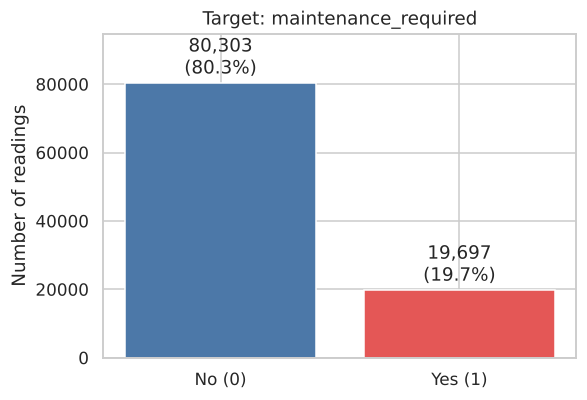

In [3]:
counts = raw[TARGET].value_counts().sort_index()
shares = raw[TARGET].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
bars = ax.bar(["No (0)", "Yes (1)"], counts.values, color=["#4C78A8", "#E45756"])
for bar, n, s in zip(bars, counts.values, shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 1000, f"{n:,}\n({s:.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Number of readings")
ax.set_title("Target: maintenance_required")
plt.tight_layout()

**Finding:** 19,697 readings (**19.7%**) need maintenance and 80,303 (80.3%) do not, roughly **1 positive for every 4 negatives**.

**Interpretation:** the classes are imbalanced. A model that always predicts "No" would be right about 80% of the time but would **never catch a machine that needs maintenance**, so plain accuracy is misleading here.

**Decision (carried into the pipeline):**
- Judge models mainly on **recall** (a missed machine means unplanned downtime), balanced against **precision** (false alarms waste technician time), plus **F1** and **PR-AUC**.
- Use **stratified** train/test splits so both sets keep the 20% positive share.
- Handle the imbalance during training (class weights or resampling).

## 2. Data quality

Before analysing patterns we check that the data can be trusted. Each check states what we looked for, what we found, and what we decided to do about it.

### 2.1 Structure and integrity

**What:** parse types, then look for duplicate rows, duplicate or out-of-order timestamps, and uneven coverage across machines.
**Why:** duplicates would inflate the data, and the time structure decides whether lag/rolling features and a time-based split make sense.

In [4]:
df = raw.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["machine_id"] = df["machine_id"].astype("category")

gaps = df["timestamp"].diff().dropna()
per_machine = df.groupby("machine_id", observed=True).size()
same_machine_gap = (df.sort_values("timestamp")
                      .groupby("machine_id", observed=True)["timestamp"].diff()
                      .dropna().dt.total_seconds() / 60)

print(f"Exact duplicate rows                : {df.duplicated().sum()}")
print(f"Duplicate timestamps                : {df['timestamp'].duplicated().sum()}")
print(f"Timestamps in ascending order       : {df['timestamp'].is_monotonic_increasing}")
print(f"Period covered                      : {df['timestamp'].min()}  ->  {df['timestamp'].max()}")
print(f"Gap between consecutive rows        : {gaps.dt.total_seconds().div(60).unique()} minute(s)")
print(f"Rows per machine (min / median / max): {per_machine.min()} / {int(per_machine.median())} / {per_machine.max()}")
print(f"Gap between readings of the SAME machine: median {same_machine_gap.median():.0f} min, mean {same_machine_gap.mean():.0f} min")

Exact duplicate rows                : 0
Duplicate timestamps                : 0
Timestamps in ascending order       : True
Period covered                      : 2025-01-01 00:00:00  ->  2025-03-11 10:39:00
Gap between consecutive rows        : [1.] minute(s)
Rows per machine (min / median / max): 1906 / 2002 / 2092
Gap between readings of the SAME machine: median 35 min, mean 50 min


**Finding:**
- No duplicate rows or timestamps; rows are in time order and **exactly one minute apart** across about 69 days.
- All 50 machines are well represented (roughly 1,900 to 2,100 rows each).
- Because a different machine reports every minute, consecutive readings of the **same** machine are on average **about 50 minutes apart**.

**Interpretation:** the file is a stream where one machine reports per minute. Per-machine lag or rolling-window features would be built from sparse, irregular points, so we should not rely on them.

**Decision:** no rows are removed at this stage. Features will be based on each reading itself, plus calendar features from `timestamp` (hour, weekday). We will consider a time-ordered train/test split in the pipeline.

### 2.2 Value ranges

**What:** summary statistics and box plots of the five sensors.
**Why:** to find physically impossible values (e.g. negative humidity) and see how spread out each sensor is.

In [5]:
summary = df[SENSORS].describe().T
summary["skew"] = df[SENSORS].skew()
summary

,count,mean,std,min,25%,50%,75%,max,skew
temperature,"86,000.000",75.034,10.036,35.550,68.280,75.090,81.780,121.940,-0.009
vibration,"100,000.000",43.324,29.134,-106.980,37.220,48.635,59.250,113.800,-2.189
humidity,"100,000.000",54.995,14.438,30.000,42.520,54.980,67.500,80.000,0.001
pressure,"100,000.000",3.000,1.152,1.000,2.000,3.010,4.000,5.000,-0.001
energy_consumption,"100,000.000",2.747,1.298,0.500,1.630,2.740,3.870,5.000,0.007


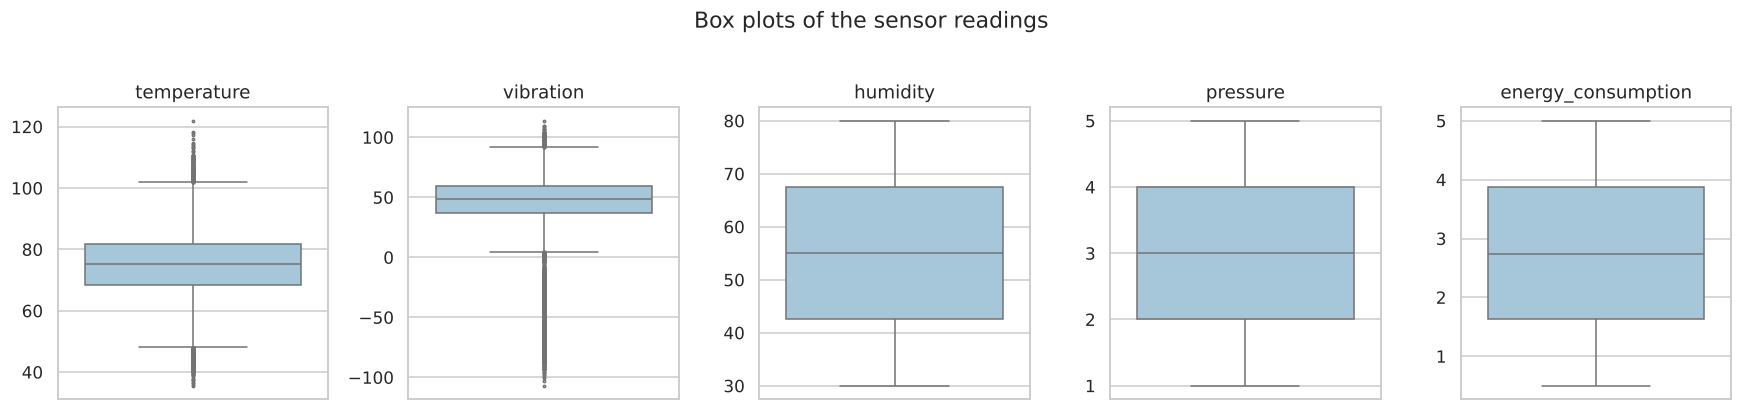

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, col in zip(axes, SENSORS):
    sns.boxplot(y=df[col], ax=ax, color="#9ecae1", fliersize=1.5)
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Box plots of the sensor readings", y=1.03)
plt.tight_layout()

**How to read the statistics:** `mean` and `50%` (the median) close together with `skew` near 0 means a roughly symmetric distribution. A large negative skew means a long tail towards low values.

**Finding:**
- `humidity` (30-80), `pressure` (1-5) and `energy_consumption` (0.5-5) stay inside tight, plausible limits, with means almost exactly at the midpoint of their range. Skew is about 0. We check their distributions properly in Section 3.
- `temperature` is symmetric (mean 75.0 °C, skew about 0). Its range of 35.6 to 121.9 °C is plausible. The hot readings look like genuine extremes rather than errors, and we will see in Section 2.4 and Section 4 that they matter.
- **`vibration` is the odd one out.** Its minimum is **-107 mm/s** and its skew is strongly negative (**-2.2**). Vibration is a magnitude, so it cannot be negative.

**Decision:** keep the extreme `temperature` values. Investigate the negative `vibration` values in Section 2.5.

### 2.3 Missing values

**What:** count missing values in every column.
**Why:** most models cannot accept missing values, and how we fill them can bias the results.

In [7]:
missing = pd.DataFrame({
    "missing_rows": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
})
missing

,missing_rows,missing_%
timestamp,0,0.000
machine_id,0,0.000
temperature,14000,14.000
vibration,0,0.000
humidity,0,0.000
pressure,0,0.000
energy_consumption,0,0.000
machine_status,0,0.000
anomaly_flag,0,0.000
predicted_remaining_life,0,0.000


**Finding:** only `temperature` has gaps: **14,000 rows (14.0%)**. Every other column is complete.

**Interpretation:** deleting 14% of the rows would throw away a lot of good information in the other columns. We need to fill the gaps, and the right method depends on **why** values are missing, which we test next.

### 2.4 Is the missing temperature random?

**What:** compare the share of missing temperatures across machine status, failure type, anomaly flag, target, machine and day, using a chi-square test of independence.
**How to read it:** the null hypothesis is "missingness is independent of this column". A **p-value above 0.05** means we found no evidence of a link; below 0.05 means the link is unlikely to be chance.
**Why:** if gaps are random, a simple fill works. If they depend on the target or on the machine's state, filling naively would distort the data.

In [8]:
df["temp_missing"] = df["temperature"].isna()
overall = df["temp_missing"].mean()

def missing_pct_by(col):
    return df.groupby(col, observed=True)["temp_missing"].mean().mul(100)

def chi2_p(col):
    return stats.chi2_contingency(pd.crosstab(df[col], df["temp_missing"]))[1]

tests = pd.DataFrame({"p_value": {c: chi2_p(c) for c in
        ["machine_status", "failure_type", "anomaly_flag", TARGET, "machine_id"]}})
tests["link_found_at_5%"] = tests["p_value"] < 0.05
tests

,p_value,link_found_at_5%
machine_status,0.828,False
failure_type,0.412,False
anomaly_flag,0.528,False
maintenance_required,0.312,False
machine_id,0.899,False


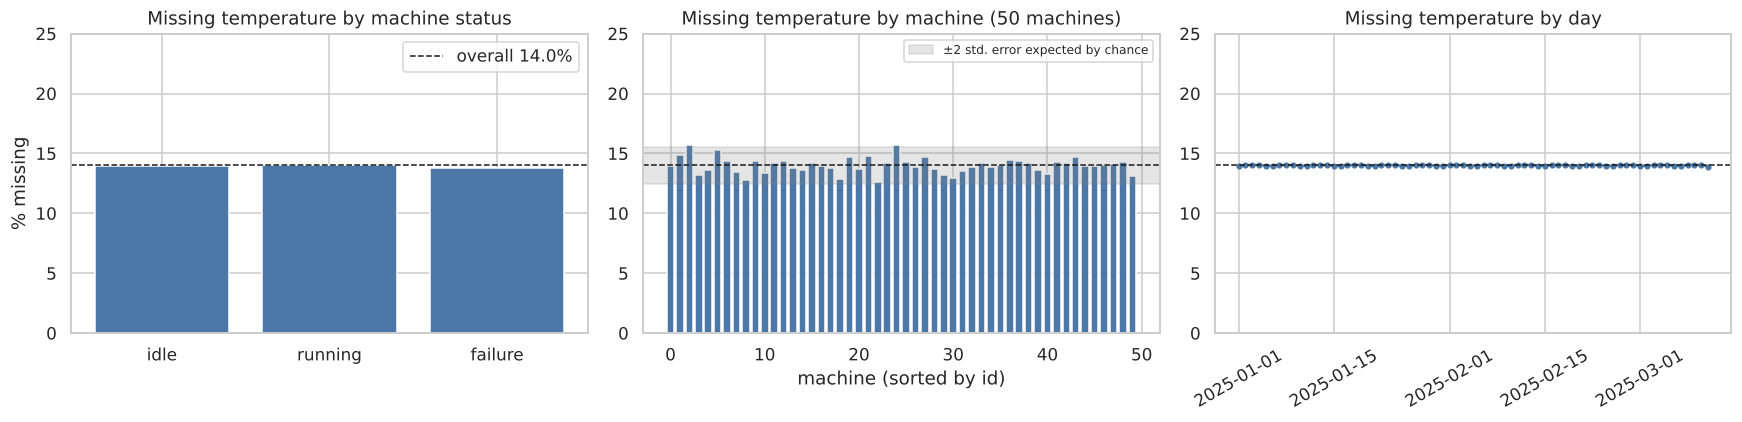

In [9]:
by_status = missing_pct_by("machine_status")
by_machine = missing_pct_by("machine_id")
by_day = df.groupby(df["timestamp"].dt.floor("D"))["temp_missing"].mean().mul(100)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(["idle", "running", "failure"], by_status.values, color="#4C78A8")
axes[0].axhline(overall * 100, color="k", ls="--", lw=1, label="overall 14.0%")
axes[0].set_title("Missing temperature by machine status")
axes[0].set_ylabel("% missing"); axes[0].set_ylim(0, 25); axes[0].legend()

se = np.sqrt(overall * (1 - overall) / per_machine.mean()) * 100
axes[1].bar(range(len(by_machine)), by_machine.values, color="#4C78A8")
axes[1].axhline(overall * 100, color="k", ls="--", lw=1)
axes[1].axhspan(overall * 100 - 2 * se, overall * 100 + 2 * se, color="grey", alpha=0.2, label="±2 std. error expected by chance")
axes[1].set_title("Missing temperature by machine (50 machines)")
axes[1].set_xlabel("machine (sorted by id)"); axes[1].set_ylim(0, 25); axes[1].legend(loc="upper right", fontsize=8)

axes[2].plot(by_day.index, by_day.values, marker="o", ms=3, color="#4C78A8")
axes[2].axhline(overall * 100, color="k", ls="--", lw=1)
axes[2].set_title("Missing temperature by day"); axes[2].set_ylim(0, 25)
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()

**Finding (missingness vs. the rest of the data):**
- All five p-values are well above 0.05: the share of missing temperatures is about 14% **whatever the machine status, failure type, anomaly flag, target value, machine or day**. Machine-to-machine variation stays inside the band expected from chance.
- So the gaps are **not related to the target** (14.1% missing for "No" vs 13.8% for "Yes").

The check below looks at the *other sensors* and at the hot readings.

In [10]:
print("Other sensors: mean value when temperature is observed vs missing")
display(df.groupby("temp_missing")[["vibration", "humidity", "pressure", "energy_consumption"]].mean())

print(f"\nAverage ABSOLUTE vibration: observed = {df.loc[~df['temp_missing'], 'vibration'].abs().mean():.1f}, "
      f"missing = {df.loc[df['temp_missing'], 'vibration'].abs().mean():.1f}")

neg_vib = df["vibration"] < 0
print("\nShare of rows with NEGATIVE vibration:")
display(pd.crosstab(df["temp_missing"], neg_vib, normalize="index").mul(100)
        .rename(columns={False: "vibration >= 0 (%)", True: "vibration < 0 (%)"}))
p_neg = stats.chi2_contingency(pd.crosstab(df["temp_missing"], neg_vib))[1]
print(f"Chi-square p-value (missing temperature vs negative vibration): {p_neg:.2e}")

hot = df["temperature"] > 90
print(f"\nObserved readings above 90 °C: {hot.sum():,} ({hot.sum() / df['temperature'].notna().sum():.1%} of observed)")
print(f"  of which flagged as an anomaly: {df.loc[hot, 'anomaly_flag'].mean():.0%}")
print(f"Anomaly rate, temperature observed vs missing: "
      f"{df.loc[~df['temp_missing'], 'anomaly_flag'].mean():.1%} vs {df.loc[df['temp_missing'], 'anomaly_flag'].mean():.1%}")

Other sensors: mean value when temperature is observed vs missing


,vibration,humidity,pressure,energy_consumption
temp_missing,,,,
False,43.774,55.000,2.998,2.751
True,40.564,54.966,3.016,2.724



Average ABSOLUTE vibration: observed = 50.0, missing = 50.1

Share of rows with NEGATIVE vibration:


vibration,vibration >= 0 (%),vibration < 0 (%)
temp_missing,,
False,93.764,6.236
True,90.429,9.571


Chi-square p-value (missing temperature vs negative vibration): 2.20e-48

Observed readings above 90 °C: 5,832 (6.8% of observed)
  of which flagged as an anomaly: 100%
Anomaly rate, temperature observed vs missing: 8.9% vs 8.8%


**Finding (a link to negative vibration):**
- **Negative vibration is much more common when temperature is missing: 9.6% vs 6.2%** (p is effectively zero). The humidity, pressure and energy means are the same in both groups, and the lower raw vibration mean when temperature is missing is fully explained by the extra negative values (the average **absolute** vibration is the same, about 50 mm/s). So the two defects seem to **share a cause** (for example a faulty reading from the same sensor unit). Neither is linked to the target.
- Readings above 90 °C (about 6.8% of the observed values) are **always** flagged as anomalies. The anomaly rate is the same (about 9%) whether temperature is observed or missing, so **a share of the missing readings were probably high temperatures** that a simple fill will pull down to the average.

**Conclusion:** missingness does not depend on the target, machine, status or time, so it is close to "missing at random". The fill will not bias the target, but it will lose the high-temperature signal for some rows.

**Decision on temperature:**
1. Fill gaps with the **median** (robust, and the distribution is symmetric). We use the **global** median because the median differs very little between machines (74.5 to 75.8 °C), so per-machine medians add complexity for no gain. In the pipeline it is **fitted on the training set only** to avoid leakage into the test set.
2. Add a **`temperature_missing` indicator** feature, so a model can learn from the fact that the reading was absent, and so the lost high-temperature signal is partly recoverable.
3. Revisit this in Section 5 once we know how the derived columns relate to temperature.

### 2.5 Negative vibration

**What:** investigate the 6,703 readings with a negative vibration value.
**Why:** vibration is a magnitude, so negatives are errors. But *what kind* of error decides the fix: if the sign was randomly flipped, the true value is recoverable (take the absolute value). If the values are junk, they should be treated as missing.
**Test:** if they are random sign flips, then `|negative values|` should follow the **same distribution** as the positive values, and negatives should not depend on machine, status or target.

In [11]:
neg = df["vibration"] < 0
pos_vals = df.loc[~neg, "vibration"]
neg_abs_vals = df.loc[neg, "vibration"].abs()

print(f"Negative readings: {neg.sum():,} ({neg.mean():.1%}),  most negative: {df['vibration'].min():.1f}")

quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
comparison = pd.DataFrame({
    "positive readings": pos_vals.quantile(quantiles),
    "|negative readings|": neg_abs_vals.quantile(quantiles),
})
comparison.index = [f"{int(q * 100)}th percentile" for q in quantiles]
comparison.loc["mean"] = [pos_vals.mean(), neg_abs_vals.mean()]
display(comparison)

ks = stats.ks_2samp(pos_vals, neg_abs_vals)
print(f"Kolmogorov-Smirnov test, positive vs |negative|: statistic = {ks.statistic:.4f}, p-value = {ks.pvalue:.3f}")

share_neg = pd.concat({c: neg.groupby(df[c], observed=True).mean().mul(100)
                       for c in ["machine_status", "failure_type", TARGET]})
print("\nShare of readings that are negative (%), by group:")
display(share_neg.rename("negative %").to_frame())

p_mach = stats.chi2_contingency(pd.crosstab(df["machine_id"], neg))[1]
print(f"Chi-square p-value, negative vibration vs machine: {p_mach:.3f}")
print(f"Correlation with target: raw vibration = {df['vibration'].corr(df[TARGET]):.3f}, "
      f"|vibration| = {df['vibration'].abs().corr(df[TARGET]):.3f}")

Negative readings: 6,703 (6.7%),  most negative: -107.0


,positive readings,|negative readings|
5th percentile,25.510,24.204
25th percentile,39.960,40.025
50th percentile,49.960,50.020
75th percentile,60.110,60.050
95th percentile,74.750,74.917
mean,50.023,49.915


Kolmogorov-Smirnov test, positive vs |negative|: statistic = 0.0099, p-value = 0.575

Share of readings that are negative (%), by group:


negative %
machine_status       0                      6.425
                     1                      6.735
                     2                      6.722
failure_type         Electrical Fault       6.903
                     Normal                 6.698
                     Overheating            6.586
                     Pressure Drop          7.110
                     Vibration Issue        6.616
maintenance_required 0                      6.712
                     1                      6.666

Chi-square p-value, negative vibration vs machine: 0.436
Correlation with target: raw vibration = 0.051, |vibration| = 0.113


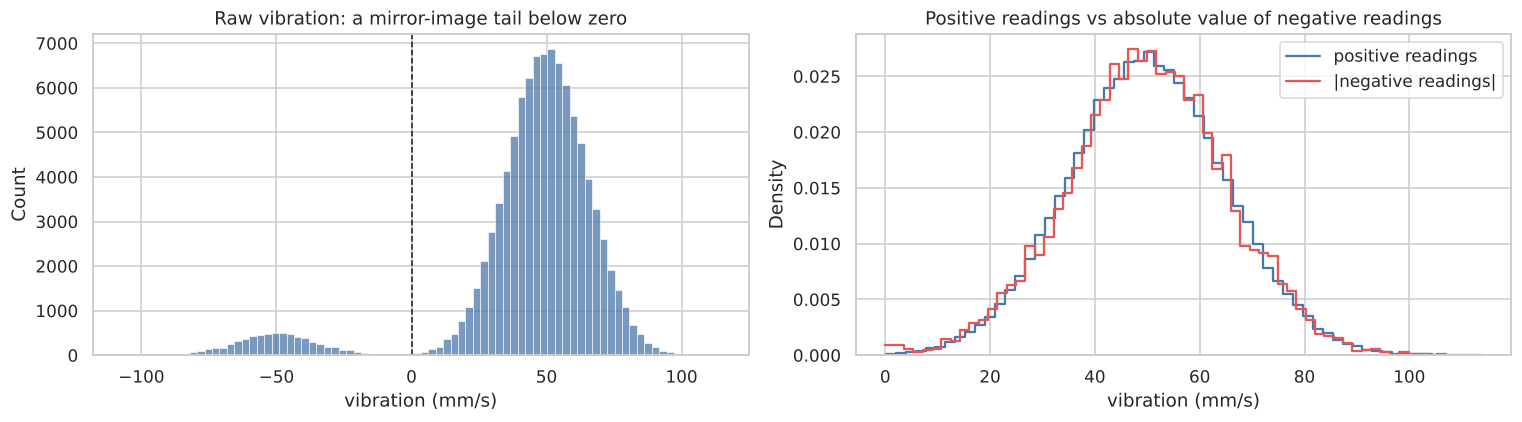

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["vibration"], bins=80, color="#4C78A8", ax=axes[0])
axes[0].axvline(0, color="k", ls="--", lw=1)
axes[0].set_title("Raw vibration: a mirror-image tail below zero")
axes[0].set_xlabel("vibration (mm/s)")

sns.histplot(pos_vals, bins=60, stat="density", element="step", fill=False,
             color="#4C78A8", label="positive readings", ax=axes[1])
sns.histplot(neg_abs_vals, bins=60, stat="density", element="step", fill=False,
             color="#E45756", label="|negative readings|", ax=axes[1])
axes[1].set_title("Positive readings vs absolute value of negative readings")
axes[1].set_xlabel("vibration (mm/s)"); axes[1].legend()
plt.tight_layout()

**How to read the Kolmogorov-Smirnov (KS) test:** it measures the largest gap between two cumulative distributions (the *statistic*, 0 = identical, 1 = completely different). A **p-value above 0.05** means we cannot tell the two samples apart.

**Finding:**
- The absolute values of the negative readings match the positive readings almost exactly: same percentiles, same mean (about 50 mm/s), and a KS statistic of about 0.01 with p = 0.58, so **no detectable difference**.
- The share of negative readings is about 6-7% in every machine status, failure type and target group, and does not depend on the machine (p = 0.44).
- Taking the absolute value **doubles the correlation with the target** (0.051 to 0.113): the sign flips were hiding a real signal.

**Conclusion:** the negative values are **random sign flips** (about 6.7% of readings), not corrupt data. The true magnitude is recoverable.

**Decision:** replace `vibration` with `abs(vibration)`. No rows are dropped.

### 2.6 Cleaning decisions applied

We now apply the three decisions to create `df_clean`, and check that the result is sound.

In [13]:
df_clean = df.drop(columns="temp_missing").copy()

# Decision 1: sign flips in vibration are recoverable
df_clean["vibration"] = df_clean["vibration"].abs()

# Decision 2: keep a flag for rows whose temperature was missing, then fill with the median
df_clean["temperature_missing"] = df_clean["temperature"].isna().astype(int)
temp_median = df_clean["temperature"].median()   # exploratory only: the pipeline fits this on the training set
df_clean["temperature"] = df_clean["temperature"].fillna(temp_median)

assert df_clean.isna().sum().sum() == 0, "missing values remain"
assert (df_clean["vibration"] >= 0).all(), "negative vibration remains"

before = pd.DataFrame({"temperature (before)": df["temperature"].describe(),
                       "temperature (after)": df_clean["temperature"].describe(),
                       "vibration (before)": df["vibration"].describe(),
                       "vibration (after)": df_clean["vibration"].describe()})
print(f"Median used for temperature: {temp_median:.2f} °C")
before

Median used for temperature: 75.09 °C


,temperature (before),temperature (after),vibration (before),vibration (after)
count,"86,000.000","100,000.000","100,000.000","100,000.000"
mean,75.034,75.042,43.324,50.016
std,10.036,9.307,29.134,14.974
min,35.550,35.550,-106.980,0.020
25%,68.280,69.500,37.220,39.970
50%,75.090,75.090,48.635,49.960
75%,81.780,80.580,59.250,60.100
max,121.940,121.940,113.800,113.800


**Check:** no missing values and no negative vibration remain. Filling with the median keeps the temperature mean unchanged (75.0 °C) but **shrinks its spread slightly** (the standard deviation drops from 10.0 to 9.3), which is the expected cost of mean-style imputation and another reason for the `temperature_missing` indicator.

### Summary of data-quality decisions

| Issue | Evidence | Decision | Why |
|---|---|---|---|
| Duplicates, timestamp problems | None found; rows exactly 1 minute apart | No action | Data is structurally sound |
| 14% of `temperature` missing | Not linked to target, machine, status or time (all p > 0.3) | Fill with the global median **and** add `temperature_missing` | Robust, simple, avoids dropping 14,000 rows |
| Negative `vibration` (6.7%) | The absolute value of the negatives has the same distribution as the positives (KS p = 0.58); not linked to any group; correlation with target doubles after correction | Replace with the absolute value | Random sign flips; the magnitude is recoverable |
| Missing temperature and negative vibration co-occur (9.6% vs 6.2%) | Chi-square p is effectively 0 | Treat as one data-quality issue; keep the indicator feature | Suggests a shared sensor fault |
| Extreme temperatures (> 90 °C) | Always flagged as anomalies | **Keep** | Genuine signal, not error |

These steps will be implemented in the pipeline's cleaning module, with the imputation value learned from the training data only.